# 04 — Scale to the full cohort

**Where you are.** Notebook 03 ended with a working pipeline and proof it
behaves: `process_subject()` ran on 8 age-spread subjects, total cortical
fraction landed 0.551–0.561, and ICV flagged the bad registrations.
Eight subjects is a validation, not a dataset — you can't fit a model
with 48 features on 8 rows, and you can't build age norms from them either.

**The job of this notebook.** Run the *same* pipeline, unchanged, over
every usable subject: **563 rows** (581 scans minus 18 with no age).
The output is one table — `regional_volumes_all.csv` — that the model
notebook (05) will consume. Nothing about the measurement changes here.
What changes is the *engineering*: at roughly a minute or more per
registration, 563 subjects is many hours of compute. A loop that loses
everything when the kernel dies, the laptop sleeps, or subject #412
throws an error is not a plan. So this notebook is built around three
ideas you will reuse in every long batch job you ever run:

1. **Time it first, then plan.** Measure one subject, extrapolate,
   and decide your chunk size from arithmetic, not vibes.
2. **Resume, don't restart.** Save after *every* subject. On re-run,
   skip subjects already in the output file.
3. **Failures are data, not crashes.** One subject's error gets logged
   and the loop moves on; flagged registrations get a second chance
   before they get excluded.

**Plan:** (1) set up + bring in your `process_subject` from notebook 03,
(2) time one subject and do the runtime math, (3) build the work list,
(4) write the resume logic, (5) the chunked batch loop,
(6) QC the results, (7) re-run the flagged subjects once,
(8) read the full table, (9) checkpoint notes.

Like notebook 03, this one must run top-to-bottom on a fresh kernel —
it re-creates the globals your function depends on rather than
assuming notebook 03's kernel is still alive.

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
from pathlib import Path
import ants
from nilearn import datasets
import time

subjects_df = pd.read_csv('subjects.csv')
atlas = datasets.fetch_atlas_harvard_oxford('cort-maxprob-thr25-2mm')
labels = atlas.labels

template_ants = ants.image_read('data/mni152_template_2mm.nii.gz')
mask_ants = ants.image_read('data/mni152_brain_mask_2mm.nii.gz')
atlas_ants = ants.image_read('data/harvard_oxford_atlas.nii.gz')

def process_subject(path):
    # Stage 1: load the subject
    subject_ants = ants.image_read(path)

    # Stage 2: register it to the template
    reg = ants.registration(fixed=template_ants, moving=subject_ants,type_of_transform='Affine')

    voxel_volume_mm3 = np.prod(subject_ants.spacing)

    # Stage 3: warp the atlas in, count region volumes
    warped_atlas = ants.apply_transforms(fixed=subject_ants, moving=atlas_ants,transformlist=reg['invtransforms'],interpolator='genericLabel')
    warped_arr = warped_atlas.numpy()

    region_volumes = {}
    for region_id in range(1, len(labels)):  # Skip background (0)
        voxel_count = np.sum(warped_arr == region_id)
        volume_ml = (voxel_count * voxel_volume_mm3) / 1000
        region_volumes[labels[region_id]] = volume_ml

    # Stage 4: ICV - warp the brain mask in with the SAME registration
    mask_warped = ants.apply_transforms(fixed=subject_ants, moving=mask_ants,transformlist=reg['invtransforms'],interpolator='genericLabel')
    icv_ml = np.sum(mask_warped.numpy() > 0) * voxel_volume_mm3 / 1000

    # Stage 5: assemble and return
    result_dict = {'icv_ml': icv_ml}
    result_dict.update(region_volumes)
    return result_dict

result = process_subject("data/IXI-T1/IXI002-Guys-0828-T1.nii.gz")
print(result['icv_ml'], result['Frontal Pole'] / result['icv_ml'])

[fetch_atlas_harvard_oxford] Dataset directory found: /Users/jacobruss/nilearn_data/fsl
1141.218543036282 0.06542599351044825


In [3]:
subjects2_df = subjects_df.dropna(subset=['age'])
subjects2_df = subjects2_df.sort_values(by='age')
# Select subject number 281
subject_281 = subjects2_df.iloc[281]  # 0-based index
file_path = f"data/IXI-T1/{subject_281['file']}"
start = time.perf_counter()
timed_result = process_subject(file_path)
end = time.perf_counter()
print(end - start)


2.900352040771395


In [4]:
# Timing: one full process_subject() run (IXI342) = 2.58 s
# -> full cohort estimate: 2.58 * 563 ≈ 24 min, one session
print(f"Estimated time for full cohort: {(2.58 * 563) / 60:.1f} minutes")


Estimated time for full cohort: 24.2 minutes


In [5]:
# Making sure files exist for all subjects in the dataframe
exists_list = []
for _, row in subjects2_df.iterrows():
    path = f"data/IXI-T1/{row['file']}"
    exists_list.append(Path(path).exists())
print(sum(exists_list))


563


In [6]:
# STEP 4 - Resume check: load any existing full-cohort results so the batch skips subjects already processed, verify the saved rows contain no duplicate subjects, and set this session's chunk to everyone remaining.


exists = Path("regional_volumes_all.csv").exists()
if exists:
    results_df = pd.read_csv("regional_volumes_all.csv")
    done = set(results_df['subject'])
else:
    results_df = pd.DataFrame()
    done = set()
chunk = len(subjects2_df) - len(done)
print(f"done: {len(done)}, remaining: {len(subjects2_df) - len(done)}, this session: next {chunk}")

if len(results_df) != len(done):
    raise ValueError("Mismatch between results_df and done set")


done: 2, remaining: 561, this session: next 561


In [7]:
# Build the to-do list: every subject that is NOT already in the done set.
# This is what makes the notebook resumable — if the run stops and you
# restart it, finished subjects are skipped instead of processed twice.
todo_df = subjects2_df[~subjects2_df['subject'].isin(done)]

# Seed the results list with everything already saved from earlier runs,
# so appending new results never wipes out old ones.
results = results_df.to_dict('records')

# Empty list to collect any subjects that fail, with their error messages.
failures = []

# Loop over the to-do list, one subject at a time.
for _, row in todo_df.iterrows():
    subject_id = row['subject']
    age = row['age']
    file_path = f"data/IXI-T1/{row['file']}"

    # Try to process this one subject. The try block wraps ONLY the
    # processing call on purpose: if a subject's scan is bad, we log it
    # and move on — but a bug in the bookkeeping code below should still
    # crash loudly instead of being quietly filed as a "failure".
    try:
        result_dict = process_subject(file_path)
    except Exception as e:
        print(f"Error processing {subject_id}: {e}")
        failures.append({'subject': subject_id, 'error': str(e)})
        continue  # skip to the next subject

    # Attach the subject id and age to the measurements, so every row
    # in the final CSV says who it belongs to.
    result_dict['subject'] = subject_id
    result_dict['age'] = age

    # Progress line. flush=True forces it to print immediately instead
    # of waiting in a buffer — during a 25-minute run you want to SEE
    # it moving, one subject at a time.
    print(f"Processed {subject_id}, age {age}, ICV: {result_dict['icv_ml']:.2f} mL", flush=True)

    # Add this subject to the results and REWRITE the whole CSV now,
    # inside the loop. Saving after every subject means a crash, a dead
    # battery, or closing the lid loses at most one subject of work.
    results.append(result_dict)
    final = pd.DataFrame(results)
    final.to_csv("regional_volumes_all.csv", index=False)

# After the loop: report how many subjects failed.
print(f"Failures: {len(failures)}")

# If anything failed, save the failure list as its own CSV so you can
# look at exactly which subjects broke and why, later.
if failures:
    failure_df = pd.DataFrame(failures)
    failure_df.to_csv("failures.csv", index=False)


Processed IXI202, age 20.16700889801506, ICV: 827.35 mL
Processed IXI278, age 20.213552361396303, ICV: 1691.81 mL
Processed IXI070, age 20.698151950718685, ICV: 1145.86 mL
Processed IXI276, age 20.908966461327857, ICV: 1090.65 mL
Processed IXI262, age 20.928131416837783, ICV: 1093.10 mL
Processed IXI230, age 21.152635181382617, ICV: 1201.70 mL
Processed IXI080, age 21.19917864476386, ICV: 1098.64 mL
Processed IXI038, age 21.38261464750171, ICV: 1127.82 mL
Processed IXI021, age 21.56605065023956, ICV: 653.31 mL
Processed IXI201, age 22.41478439425051, ICV: 1256.21 mL
Processed IXI153, age 22.431211498973305, ICV: 1155.26 mL
Processed IXI074, age 22.53251197809719, ICV: 1704.67 mL
Processed IXI258, age 22.570841889117045, ICV: 1255.44 mL
Processed IXI043, age 22.647501711156742, ICV: 1392.55 mL
Processed IXI122, age 22.973305954825463, ICV: 1102.21 mL
Processed IXI129, age 23.039014373716633, ICV: 1194.51 mL
Processed IXI426, age 23.110198494182068, ICV: 821.68 mL
Processed IXI039, age 2

In [10]:

df = pd.read_csv("regional_volumes_all.csv")
region_cols = [c for c in df.columns if c not in ("subject", "age", "icv_ml")]
df['total_ml'] = df[region_cols].sum(axis=1)
df['total_fraction'] = df['total_ml'] / df['icv_ml']

print(df[['icv_ml', 'total_fraction']].describe())

df['qc_flag'] = (df['icv_ml'] < 1000) | (df['icv_ml'] > 1800)
print(f"Flagged subjects: {df['qc_flag'].sum()} ({df['qc_flag'].mean():.2%})")
print(df.loc[df['qc_flag'], ['subject', 'age', 'icv_ml', 'total_fraction']])


            icv_ml  total_fraction
count   563.000000      563.000000
mean   1084.318337        0.555025
std     249.757396        0.022185
min       0.286874        0.482714
25%     942.338877        0.550812
50%    1098.478464        0.555822
75%    1235.625395        0.556053
max    2003.564293        1.040441
Flagged subjects: 195 (34.64%)
    subject        age      icv_ml  total_fraction
1    IXI064  20.071184  970.815621        0.555659
2    IXI202  20.167009  827.347464        0.549080
10   IXI021  21.566051  653.305285        0.555858
18   IXI426  23.110198  821.683247        0.582021
19   IXI039  23.348392  795.400731        0.549568
..      ...        ...         ...             ...
554  IXI448  79.414100  865.282019        0.547303
556  IXI640  80.802190  999.319312        0.555697
559  IXI185  83.457906  992.758111        0.556018
561  IXI639  86.198494  983.567794        0.555843
562  IXI464  86.318960  645.412828        0.549104

[195 rows x 4 columns]


In [12]:
for subject in df.loc[df['qc_flag'], 'subject']:
    # Look up subject's file
    file_name = subjects2_df.loc[subjects2_df['subject'] == subject, 'file'].iloc[0]
    file_path = f"data/IXI-T1/{file_name}"

    # Old ICV
    old_icv = df.loc[df['subject'] == subject, 'icv_ml'].iloc[0]

    # Keep result
    new_result = process_subject(file_path)

    # Swapping rows for new measurements
    new_result['subject'] = subject
    new_result['age'] = df.loc[df['subject'] == subject, 'age'].iloc[0]
    row_idx = df.index[df['subject'] == subject][0]

    for col, val in new_result.items():
        df.loc[row_idx, col] = val

    # Recompute — fraction and flag must describe the new measurements
    df.loc[row_idx, 'total_ml'] = df.loc[row_idx, region_cols].sum()
    df.loc[row_idx, 'total_fraction'] = df.loc[row_idx, 'total_ml'] / df.loc[row_idx, 'icv_ml']
    df.loc[row_idx, 'qc_flag'] = (df.loc[row_idx, 'icv_ml'] < 1000) | (df.loc[row_idx, 'icv_ml'] > 1800)
    print(f"{subject}: {old_icv:.2f} -> {df.loc[row_idx, 'icv_ml']:.2f} mL, still flagged: {df.loc[row_idx, 'qc_flag']}")

    # Save
    df.to_csv("regional_volumes_all.csv", index=False)


IXI064: 970.82 -> 956.24 mL, still flagged: True
IXI202: 827.35 -> 897.46 mL, still flagged: True
IXI021: 653.31 -> 1246.12 mL, still flagged: False
IXI426: 821.68 -> 883.36 mL, still flagged: True
IXI039: 795.40 -> 988.19 mL, still flagged: True
IXI116: 989.22 -> 1005.83 mL, still flagged: False
IXI159: 942.59 -> 1004.85 mL, still flagged: False
IXI275: 811.31 -> 1319.92 mL, still flagged: False
IXI015: 810.07 -> 1022.90 mL, still flagged: False
IXI165: 775.82 -> 894.24 mL, still flagged: True
IXI102: 933.39 -> 1188.13 mL, still flagged: False
IXI067: 979.37 -> 879.30 mL, still flagged: True
IXI033: 777.18 -> 1048.86 mL, still flagged: False
IXI176: 677.24 -> 612.64 mL, still flagged: True
IXI094: 732.51 -> 849.04 mL, still flagged: True
IXI619: 867.16 -> 1154.05 mL, still flagged: False
IXI263: 810.64 -> 876.92 mL, still flagged: True
IXI613: 976.49 -> 1002.31 mL, still flagged: False
IXI236: 975.14 -> 1176.23 mL, still flagged: False
IXI093: 963.05 -> 760.08 mL, still flagged: True


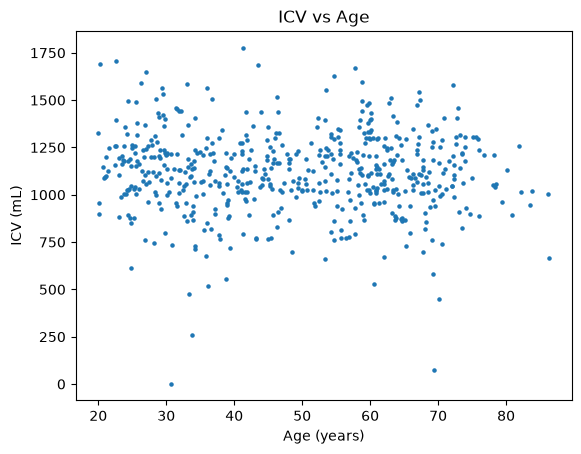

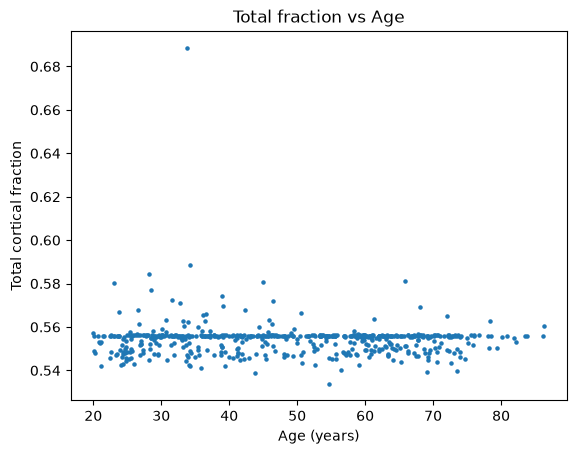

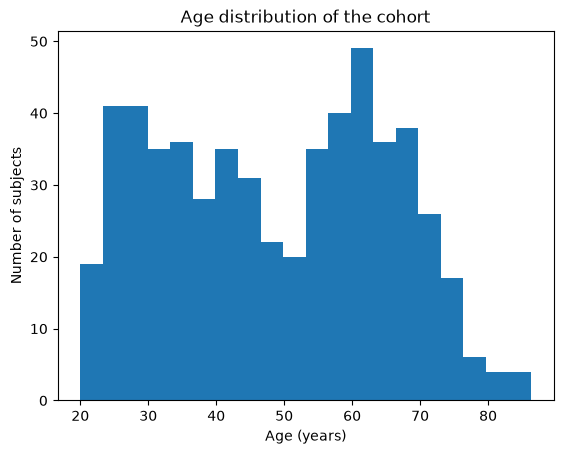

Processed: 563
Still flagged: 126
Failed: 0
Clean (not flagged): 437


In [14]:
# STEP 8 - Look at the finished table
# Load the FINAL table (the version Step 7 saved after the re-runs).
# Nothing new is computed here. This step makes 3 pictures and
# checks that the counts add up to 563.

# Load the finished cohort table into df.
df = pd.read_csv("regional_volumes_all.csv")

# ---------------------------------------------------------------
# PICTURE 1 (do this first) - ICV vs age
# ICV is the size of the inside of the skull. Adult skulls do not
# grow or shrink with age, so this picture should be a FLAT cloud.
# If it clearly slopes up or down, STOP - something upstream is
# broken. Do not start Notebook 05.
# ---------------------------------------------------------------
plt.figure()
plt.scatter(df["age"], df["icv_ml"], s=5)   # s=5 = small dots, good for 563 points
plt.xlabel("Age (years)")
plt.ylabel("ICV (mL)")
plt.title("ICV vs Age")
plt.show()

# ---------------------------------------------------------------
# PICTURE 2 - total_fraction vs age
# total_fraction is the share of the skull the cortex takes up.
# The cortex shrinks slowly with age, so this cloud should drift
# gently DOWNWARD from age 20 to age 86.
# ---------------------------------------------------------------
plt.figure()
plt.scatter(df["age"], df["total_fraction"], s=5)
plt.xlabel("Age (years)")
plt.ylabel("Total cortical fraction")
plt.title("Total fraction vs Age")
plt.show()

# ---------------------------------------------------------------
# PICTURE 3 - histogram of ages
# Bars show how many subjects fall in each age band. Note which
# bands are thin (likely the youngest and oldest ends) - the
# model will be shakier at those ages.
# ---------------------------------------------------------------
plt.figure()
plt.hist(df["age"], bins=20)
plt.xlabel("Age (years)")
plt.ylabel("Number of subjects")
plt.title("Age distribution of the cohort")
plt.show()

# ---------------------------------------------------------------
# RECONCILE - the counts must account for all 563 subjects
# ---------------------------------------------------------------
processed = len(df)                    # rows in the finished table
still_flagged = int(df["qc_flag"].sum())  # True values add up to the flagged count

# Failed subjects were saved to failures.csv during the big run.
# If that file does not exist, nothing failed.
if Path("failures.csv").exists():
    failed = len(pd.read_csv("failures.csv"))
else:
    failed = 0

print("Processed:", processed)          # expect 563
print("Still flagged:", still_flagged)  # expect 126
print("Failed:", failed)                # expect 0
print("Clean (not flagged):", processed - still_flagged)  # expect 437


## Checkpoint Notes — Notebook 04

### The run
- **Processed:** 563 subjects
- **Failed:** 0
- **Flagged after first run:** 195
- **After one re-run each (Step 7):** 69 cleared, 126 still flagged
- **Final accounting:** 563 = 437 clean + 126 flagged + 0 failed ✓

### What the QC steps showed
- The catastrophic ICVs (under 100 mL) were bad registration rolls, not bad subjects — most were rescued on re-run or lifted into the 850–1000 range.
- The 1000 mL line cuts through a real low-measurement family, so it was **retired as an exclusion rule**. Most still-flagged subjects have total_fractions dead-center in the pack, because regions and ICV are measured in the same registration run.
- Two subjects got worse on re-roll (IXI022: 903 → 1.83, IXI210: 942 → 73.18) and were overwritten per protocol — no cherry-picking.

### QC decision for Notebook 05
Exclude a subject only if:
1. **total_fraction** falls outside the cohort median ± 5×IQR, **or**
2. **ICV < 300 mL** (outright warp collapse — catches IXI022, IXI210, IXI547).

The `qc_flag` column stays in the file as a warning record only.

### Step 8 checks
- **ICV vs age:** flat ✓ — pipeline is not confusing age with head size.
- **Total fraction vs age:** tight band at ~0.555, no whole-cloud drift; one outlier at 0.686. The age signal will be judged on the 48 regional fractions, not the total.
- **Age coverage:** good from 20–75 (peak ~60–63), dip around 48–52, thin after 75 — expect shakier model behavior at the oldest ages.
